# AgriLens — Real Tanager-1 Hyperspectral Demonstration

**Open-data, 813-oriented PoC.** The actual sample is **Tanager-1 over Campo Verde, Brazil, 2025-05-01**, not the Nile Delta and **not Satellite 813**. Source: [Planet hands-on vegetation tutorial](https://planetlabs.github.io/tanager-opendata-edu/module-4/spectral-indices-p2/).

This notebook does not simulate real satellite measurements: it must download/read an actual `.h5` before plots appear.

## 1. Setup and exact open-data scene

The public Planet orthorectified surface-reflectance HDF5 is potentially large. Download only this one scene, **not** the global archive. You may place the real `.h5` manually in the `data/` folder if automatic download fails.

In [1]:
from pathlib import Path
import os, subprocess, sys, json
ROOT=next((p for p in [Path.cwd(), Path.cwd()/"AgriLens_Hyperspectral_PoC", Path.cwd().parent] if (p/"src"/"tanager_hsi.py").exists()), None)
assert ROOT is not None, "Extract package and run in its directory (or /content/AgriLens_Hyperspectral_PoC on Colab)"
os.chdir(ROOT)
SCENE="20250501_143138_87_4001"
HSI_FILE=Path(os.environ.get("AGRILENS_HSI_FILE", f"data/{SCENE}_ortho_sr_hdf5.h5"))
OUTPUT=Path("output/tanager_brazil")
print("Working directory:",Path.cwd())
print("HSI path:",HSI_FILE)

Working directory: C:\Users\Lenovo\Downloads\AgriLens_Dust_Drought_v2
HSI path: data\20250501_143138_87_4001_ortho_sr_hdf5.h5


## 2. Download genuine surface-reflectance data

This is an actual open Planet asset. If downloading fails because of network restrictions, **stop** and download the file locally before continuing. Do not substitute dummy arrays.

In [2]:
if not HSI_FILE.exists():
    subprocess.run([sys.executable,"-m","src.tanager_hsi","download","--out",str(HSI_FILE)],check=True)
assert HSI_FILE.exists() and HSI_FILE.stat().st_size > 100, "No actual downloaded HDF5 available"
print(f"File exists: {HSI_FILE}, bytes={HSI_FILE.stat().st_size:,}")

File exists: data\20250501_143138_87_4001_ortho_sr_hdf5.h5, bytes=1,047,878,062


## 3. Inspect HDF5 sensor metadata

In [3]:
subprocess.run([sys.executable,"-m","src.tanager_hsi","inspect","--h5",str(HSI_FILE)],check=True)

CompletedProcess(args=['C:\\Users\\Lenovo\\Downloads\\AgriLens_Dust_Drought_v2\\.venv\\Scripts\\python.exe', '-m', 'src.tanager_hsi', 'inspect', '--h5', 'data\\20250501_143138_87_4001_ortho_sr_hdf5.h5'], returncode=0)

## 4. Apply quality masks, calculate indices and extract spectral signatures

The two spectral groups are NDVI percentiles—**not** stress classes. The HDF5 must contain reflectance, actual band wavelengths and real cloud/cirrus/NoData masks.

In [4]:
subprocess.run([sys.executable,"-m","src.tanager_hsi","process","--h5",str(HSI_FILE),"--out",str(OUTPUT),"--scene-id",SCENE,"--stride","5"],check=True)

CompletedProcess(args=['C:\\Users\\Lenovo\\Downloads\\AgriLens_Dust_Drought_v2\\.venv\\Scripts\\python.exe', '-m', 'src.tanager_hsi', 'process', '--h5', 'data\\20250501_143138_87_4001_ortho_sr_hdf5.h5', '--out', 'output\\tanager_brazil', '--scene-id', '20250501_143138_87_4001', '--stride', '5'], returncode=0)

## 5. Review the real results

A spectral comparison from a single date is evidence of measured variation, not evidence of crop-health diagnosis or forecasting.

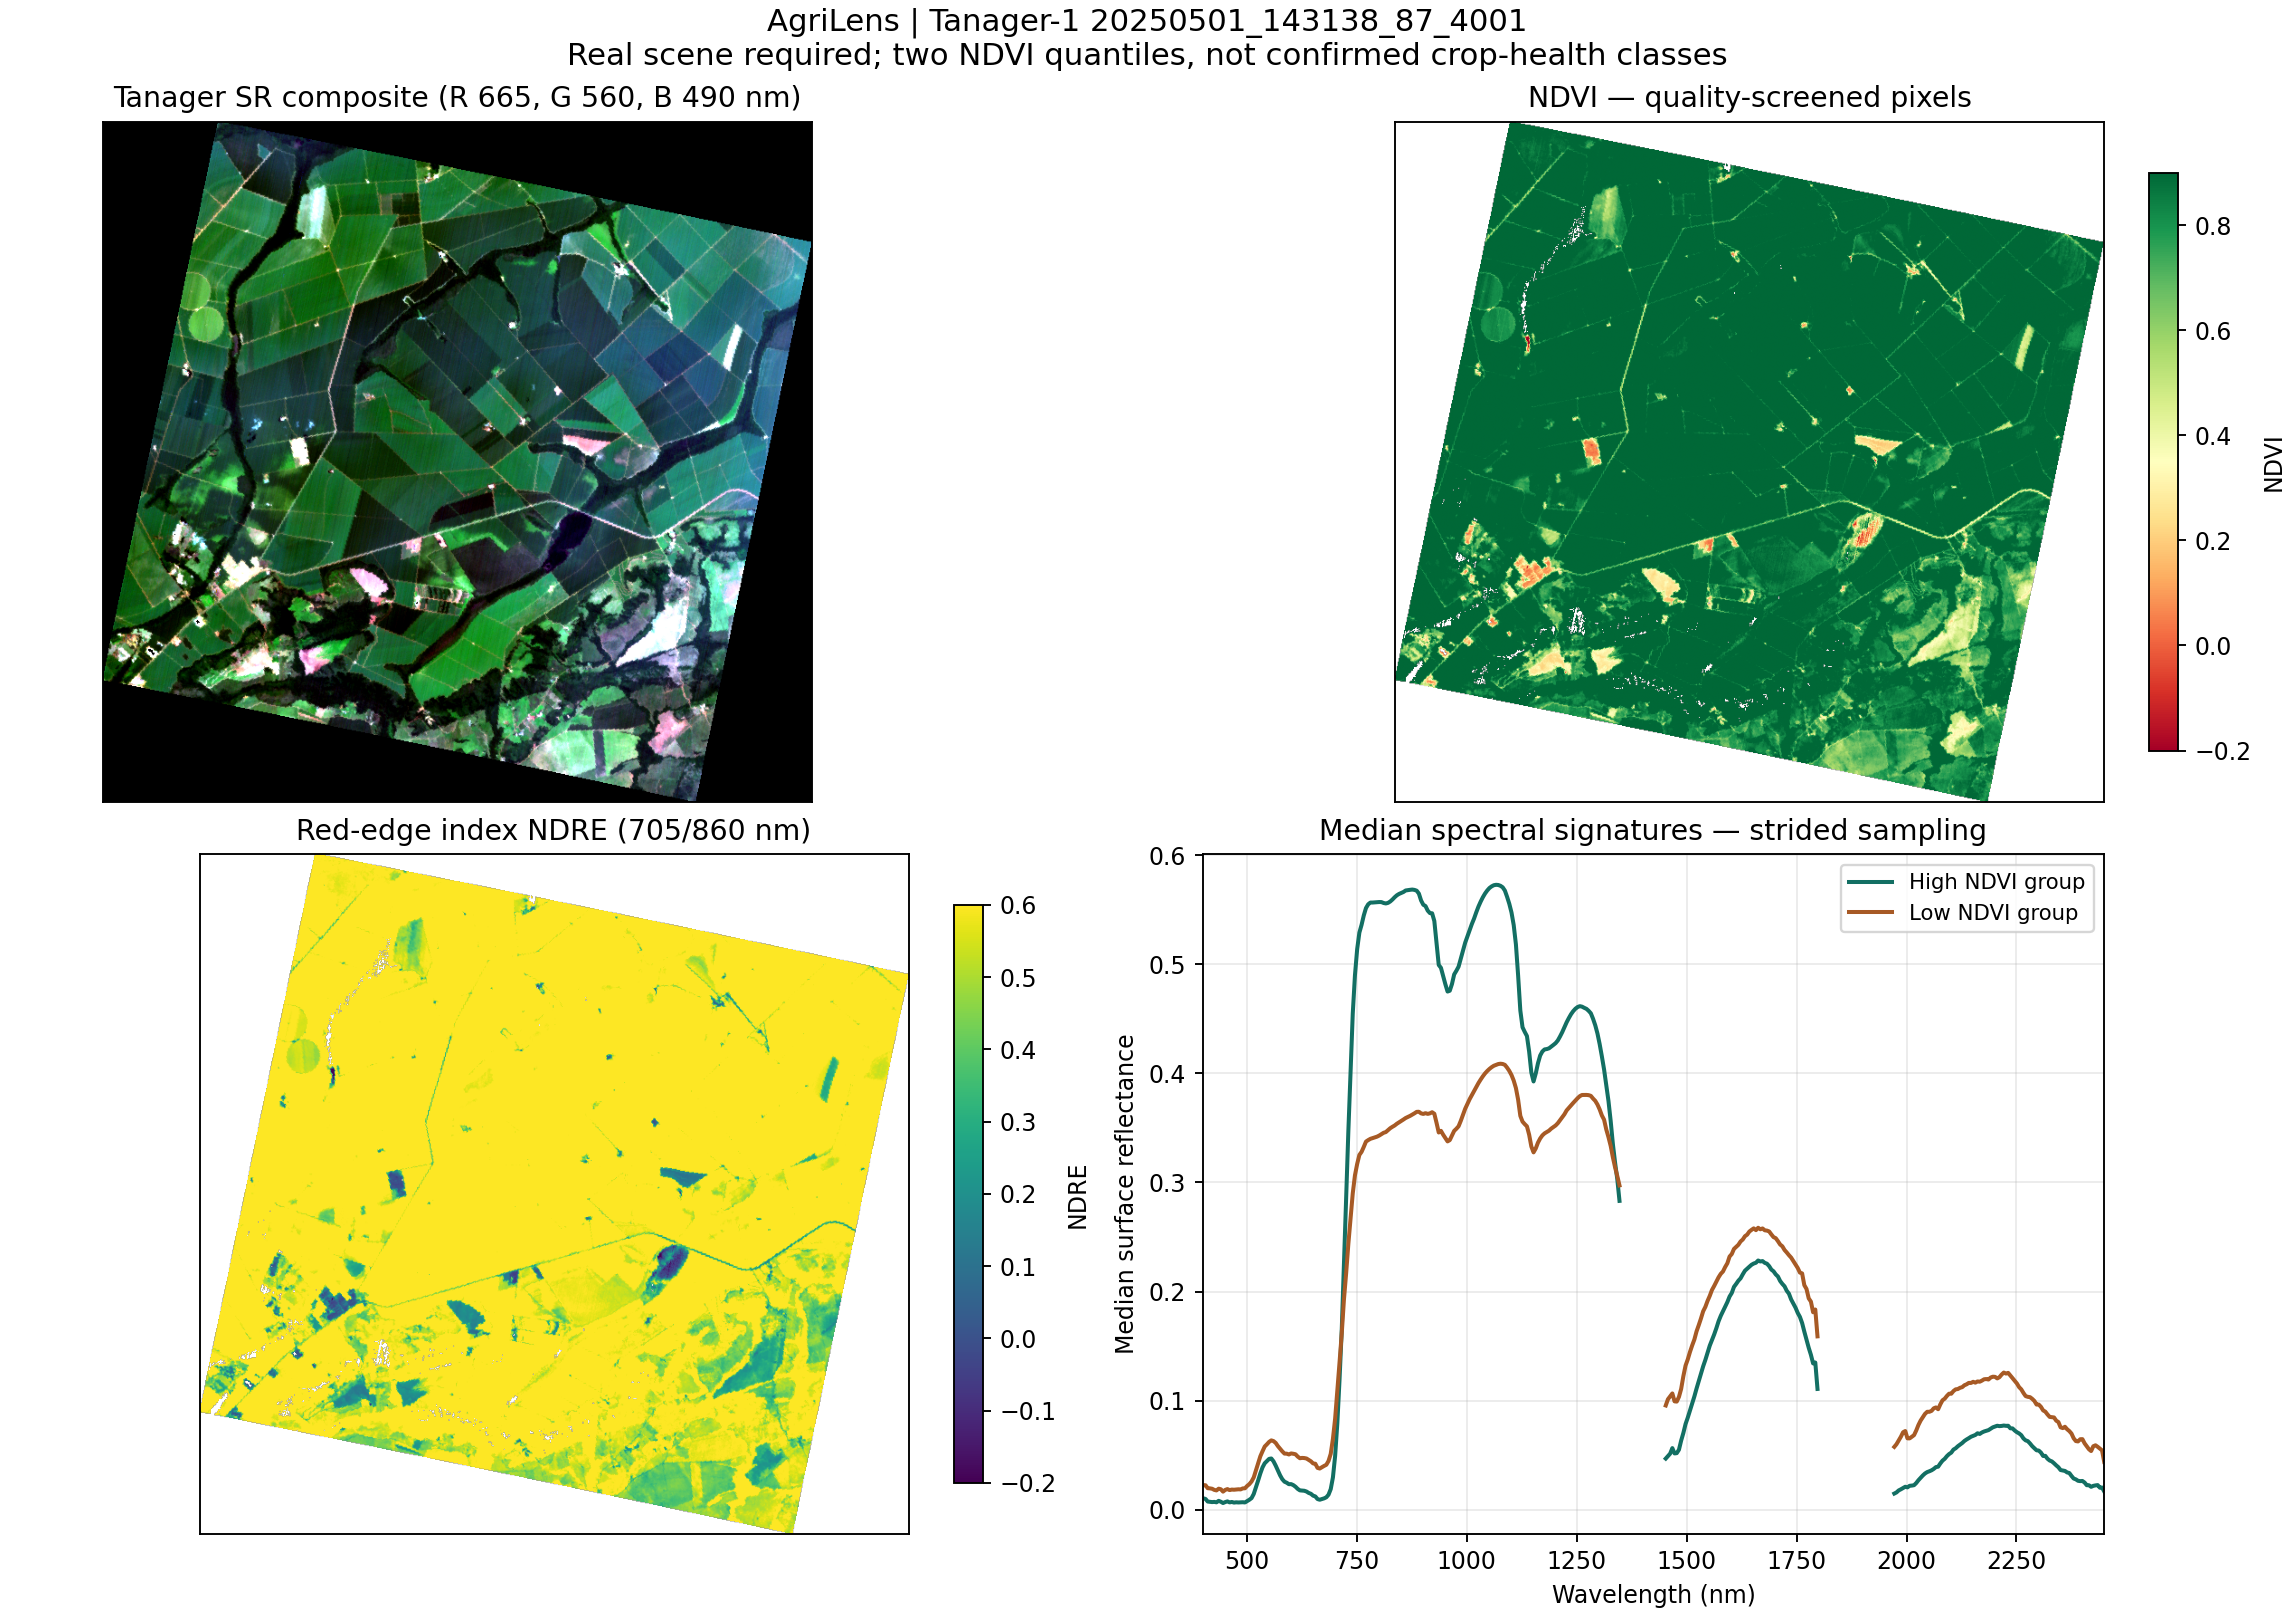

Valid pixel fraction: 0.7138684596178897
Selected wavelengths (nm): {'blue': 490.92999267578125, 'green': 560.8300170898438, 'red': 665.8699951171875, 'red_edge': 705.9199829101562, 'nir': 861.260009765625, 'swir': 1647.6600341796875}
Red-edge inflection estimates (nm): {'low_ndvi': 715.9400024414062, 'high_ndvi': 725.9600219726562}


In [5]:
from IPython.display import display, Image
display(Image(filename=str(OUTPUT / "hyperspectral_analysis.png")))
report=json.loads((OUTPUT/"processing_report.json").read_text())
print("Valid pixel fraction:",report["quality"]["valid_index_fraction"])
print("Selected wavelengths (nm):", report["spectral_processing"]["wavelength_selected_nm"])
print("Red-edge inflection estimates (nm):", report["spectral_processing"]["red_edge_inflection_nm"])

## 6. Export integration files / read signatures

In [6]:
import pandas as pd
signatures=pd.read_csv(OUTPUT/"spectral_signatures.csv")
display(signatures.head())
print("Files for Nour / the main notebook:")
for p in sorted(OUTPUT.iterdir()):print(" ",p.name, "—",p.stat().st_size,"bytes")

,wavelength_nm,median_reflectance_high_ndvi,median_reflectance_low_ndvi
0,401.290009,0.010404,0.022548
1,406.260010,0.009870,0.022391
2,411.230011,0.007466,0.019693
3,416.209991,0.007180,0.019540
4,421.179993,0.006966,0.019198


Files for Nour / the main notebook:
  hyperspectral_analysis.png — 1744291 bytes
  index_maps.npz — 3864662 bytes
  processing_report.json — 3336 bytes
  spectral_signatures.csv — 14760 bytes


## 7. Scientific limitations and connection to AgriLens

- This Tanager scene is in **Brazil**; the previously analyzed Sentinel-2 field dataset is in **Egypt**. No direct spatial/sensor-performance comparison is supported.
- NDVI strata are only descriptive. No stress, dust, disease or crop-type labels are available.
- This notebook uses no Satellite 813 pixels. 813-specific input decoding, calibration and validation remain future work.
- Open Planet data license/attribution must be confirmed for any republished imagery.

For the PoC submission, retain the generated QA report and actual-source citation; do not upload a large raw HDF5 to GitHub.